# Estudio Analítico de A/B Testing: Optimización de Tasa de Conversión y Ticket Promedio en E-Commerce

**Autora:** Alison Ixchel Maertens Gaona  
**Enfoque:** Análisis Estadístico Inferencial & Evaluación de Cohortes

El objetivo de este estudio es analizar el comportamiento de los usuarios expuestos a dos versiones de la página de inicio (A: Control vs. B: Variante) a partir del dataset landing_experiment.csv.

***Estructura del Análisis:***
- **Validación de Integridad y SRM:** Verificación de aleatorización, datos nulos y consistencia de datos.
- **Evaluación de Gasto (AOV):** Comparación paramétrica/no paramétrica del gasto promedio por usuario.
- **Tasa de Conversión (CR):** Análisis de proporciones entre versiones A y B.
- **Análisis Cohortes y Tráfico:** Evaluación de interacción entre tipo de usuario, canal de origen y rendimiento del experimento.

## Carga y Validación de Datos

In [1]:
# importar librerías
import pandas as pd
from scipy.stats import levene, ttest_ind
from statsmodels.stats.proportion import proportions_ztest
from scipy.stats import chi2_contingency
import matplotlib.pyplot as plt
import seaborn as sns

import numpy as np
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Configuración de estilo visual para informe ejecutivo
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

In [2]:
# cargar archivo
df = pd.read_csv('/datasets/landing_experiment.csv')

**Vista previa e información general del conjunto de datos**

In [3]:
# mostrar las primeras 5 filas
df.head()

,user_id,date,landing,region,dispositivo,traffic_source,user_type,converted,gasto
0,26f3052e-8500-44ea-8fff-06de65258abb,2026-01-01,A,Norte,Mobile,Email,Recurrente,1,38.08
1,92378c09-4bbf-40c7-945e-82b84f392d22,2026-01-23,A,Occidente,Mobile,Organic,Nuevo,0,0.00
2,a4397360-40e5-45d6-a7ff-dcb4da2c9a1f,2026-01-01,B,Centro,Mobile,Organic,Nuevo,0,0.00
3,7ca3a26f-1e6c-44aa-9b09-b8cb01112956,2026-01-22,A,Centro,Mobile,Ads,Nuevo,0,0.00
4,8dc9593b-5b9c-479d-848b-a99493920419,2026-01-16,A,Sur,Mobile,Organic,Nuevo,0,0.00


In [4]:
# información general
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   user_id         40000 non-null  object 
 1   date            40000 non-null  object 
 2   landing         40000 non-null  object 
 3   region          40000 non-null  object 
 4   dispositivo     40000 non-null  object 
 5   traffic_source  40000 non-null  object 
 6   user_type       40000 non-null  object 
 7   converted       40000 non-null  int64  
 8   gasto           40000 non-null  float64
dtypes: float64(1), int64(1), object(7)
memory usage: 2.7+ MB


**Hallazgos sobre la Estructura de Datos:**
El dataset cuenta con 40,000 registros y 0 valores nulos. Se identifican las siguientes acciones de preparación:
- **Columna `date`:** Se transformará de texto (`object`) a formato `datetime` para permitir análisis de tendencias y coherencia temporal.
- **Columna `converted`:** Registrada en formato binario ($0 / 1$). Adecuada para cálculo de tasas e inferencia estadística.

**Descripción del conjunto de datos**

El dataset contiene las siguientes columnas:

- `user_id` — Identificador único del usuario
- `date` — Fecha en la que el usuario fue expuesto a la página
- `landing` — Versión de la página mostrada al usuario
- `region` — Región geográfica del usuario
- `dispositivo` — Tipo de dispositivo utilizado por el usuario
- `traffic_source` — Canal por el que llegó el usuario
- `user_type` — Tipo de usuario según historial previo
- `converted` — Indica si el usuario realizó una conversión
- `gasto` — Monto gastado por el usuario (0 si no convirtió)

### Exploración Multivariada y Control de Calidad de Datos

Se valida la integridad del conjunto de datos mediante la verificación de usuarios únicos, la amplitud del período de prueba y el balance en la asignación de variantes (Experimento A/B).

 **Variable `user_id`**  
 Verificar usuarios únicos

In [5]:
df['user_id'].describe()

count                                    40000
unique                                   40000
top       1a790cd6-62fb-43ae-aabc-e1a7772c4aa8
freq                                         1
Name: user_id, dtype: object

 **Variable `date`**  
Explorar rango de fechas

In [6]:
# Conversión de tipos de datos y control de unicidad
df['date'] = pd.to_datetime(df['date'])

print(f"Total de registros: {len(df):,}")
print(f"Usuarios únicos: {df['user_id'].nunique():,}")
print(f"Rango temporal del experimento: {df['date'].min().strftime('%Y-%m-%d')} al {df['date'].max().strftime('%Y-%m-%d')}")

Total de registros: 40,000
Usuarios únicos: 40,000
Rango temporal del experimento: 2026-01-01 al 2026-01-28


In [7]:
# Identificar rango temporal del experimento
print("Fecha mínima:", df["date"].min())
print("Fecha máxima:", df["date"].max())

Fecha mínima: 2026-01-01 00:00:00
Fecha máxima: 2026-01-28 00:00:00


**Variable `gasto` (numérica)**

In [8]:
# Resumen estadístico del gasto general vs. usuarios convertidos
gasto_general = df['gasto'].describe()
gasto_convertidos = df[df['converted'] == 1]['gasto'].describe()

pd.DataFrame({'Gasto Total': gasto_general, 'Gasto (Solo Convertidos)': gasto_convertidos})

,Gasto Total,Gasto (Solo Convertidos)
count,40000.000000,5706.000000
mean,9.325554,65.373668
std,25.667986,30.896545
min,0.000000,12.120000
25%,0.000000,42.950000
50%,0.000000,59.860000
75%,0.000000,80.370000
max,303.680000,303.680000


 **Variables categóricas**  
 Verificar categorías esperadas del experimento ( A y B).

In [9]:
# Evaluación del balance de la prueba (Sample Ratio Mismatch check)
print("=== Asignación del Experimento (Landing Page) ===")
print(df['landing'].value_counts())
print(df['landing'].value_counts(normalize=True).map('{:.2%}'.format))

# Distribución de variables categóricas
columnas_categoricas = ['traffic_source', 'user_type', 'region', 'dispositivo']

for col in columnas_categoricas:
    print(f"\n--- Distribución por: {col} ---")
    print(df[col].value_counts(dropna=False))
    print(df[col].value_counts(normalize=True).map('{:.2%}'.format))

=== Asignación del Experimento (Landing Page) ===
B    20018
A    19982
Name: landing, dtype: int64
B    50.04%
A    49.95%
Name: landing, dtype: object

--- Distribución por: traffic_source ---
Organic     17987
Ads         11935
Email        6123
Referral     3955
Name: traffic_source, dtype: int64
Organic     44.97%
Ads         29.84%
Email       15.31%
Referral     9.89%
Name: traffic_source, dtype: object

--- Distribución por: user_type ---
Nuevo         26033
Recurrente    13967
Name: user_type, dtype: int64
Nuevo         65.08%
Recurrente    34.92%
Name: user_type, dtype: object

--- Distribución por: region ---
Norte        11166
Centro        9613
Sur           8039
Occidente     6398
Oriente       4784
Name: region, dtype: int64
Norte        27.91%
Centro       24.03%
Sur          20.10%
Occidente    16.00%
Oriente      11.96%
Name: region, dtype: object

--- Distribución por: dispositivo ---
Mobile     24829
Desktop    15171
Name: dispositivo, dtype: int64
Mobile     62.07%

In [10]:
# Verificación formal de SRM (Sample Ratio Mismatch)
from scipy.stats import chisquare
conteos = df['landing'].value_counts().sort_index()
chi2_srm, p_srm = chisquare(conteos)
print(f"Chi2 SRM: {chi2_srm:.4f} | Valor P: {p_srm:.4f}")

Chi2 SRM: 0.0324 | Valor P: 0.8572


#### 📌 Diagnóstico de Calidad y Validez del Experimento

* **Unicidad e Integridad:** Se confirmó una muestra exacta de 40,000 usuarios únicos (`user_id`), descartando registros duplicados o usuarios expuestos a múltiples variantes.
* **Periodo Operativo:** El experimento se mantuvo activo durante 28 días consecutivos (del 1 al 28 de enero de 2026).
* **Verificación de SRM (Sample Ratio Mismatch):** La distribución entre la versión Control (A) y Variante (B) está perfectamente balanceada al 50/50, garantizando la validez estadística para inferencia.
* **Segmentación de Tráfico y Dispositivos:**
  * **Tráfico:** Alta concentración en tráfico Orgánico (44.97%) y Ads/Paid (29.84%).
  * **Usuarios:** Prevalencia de usuarios Nuevos (65.08%) sobre Recurrentes (34.92%).
  * **Geografía:** La representación geográfica abarca 5 regiones principales, concentrando la mayor cuota en el Norte (27.92%) y Centro (24.03%), seguidos del Sur (20.10%), Occidente (16.00%) y Oriente (11.97%).

  * **Dispositivo:** Uso mayoritario de dispositivos Móviles (62.07%), lo que convierte al diseño *Responsive/Mobile-First* en un factor crítico de conversión.
* **Estructura del Gasto:** La variable `gasto` presenta una alta asimetría positiva debido a la densidad de ceros ($85\%+$ no convertidos). El análisis de Ticket Promedio (AOV) debe realizarse filtrando estrictamente la cohorte con `converted == 1`.

## Comparación del Ticket Promedio (AOV) por Versión de Página

Se evalúa si existen diferencias estadísticamente significativas en el gasto promedio de los **usuarios convertidos** entre la versión Control (A) y la Variante (B), con el fin de determinar qué diseño genera mayor valor económico.

In [11]:
# Extracción del gasto de usuarios convertidos por variante
gasto_A = df[(df['converted'] == 1) & (df['landing'] == 'A')]['gasto']
gasto_B = df[(df['converted'] == 1) & (df['landing'] == 'B')]['gasto']

print(f"Muestra de usuarios convertidos — Versión A: {len(gasto_A):,} | Versión B: {len(gasto_B):,}")

Muestra de usuarios convertidos — Versión A: 2,512 | Versión B: 3,194


### Inferencia Estadística: Prueba de Hipótesis para Medias

**Planteamiento de Hipótesis:**
* **Hipótesis Nula ($H_0$):** No existe diferencia significativa en el gasto promedio entre la versión A y B.
* **Hipótesis Alternativa ($H_1$):** Existe una diferencia estadísticamente significativa en el gasto promedio entre la versión A y B.

In [12]:
# Prueba de Levene para evaluar la homogeneidad de varianzas
levene_stat, levene_p = levene(gasto_A, gasto_B)

print("--- PRUEBA DE HOMOGENEIDAD DE VARIANZAS (LEVENE) ---")
print(f"Estadístico de Levene: {levene_stat:.4f}")
print(f"Valor P (Levene): {levene_p:.4e}")

# Determinar de forma dinámica el valor de equal_var
if levene_p < 0.05:
    equal_variance = False
    print("Interpretación Levene: Se rechaza H0 (p < 0.05). Las varianzas son heterogéneas. Se usará equal_var=False (Welch t-test).")
else:
    equal_variance = True
    print("Interpretación Levene: No se rechaza H0 (p >= 0.05). Las varianzas son homogéneas. Se usará equal_var=True.")

    # Aplicar la prueba t de Student ajustada segun el resultado de Levene
t_stat, p_value = ttest_ind(gasto_A, gasto_B, equal_var=equal_variance)

print("\n--- RESULTADOS DE LA PRUEBA T DE STUDENT ---")
print(f"Gasto promedio Versión A: ${gasto_A.mean():.2f}")
print(f"Gasto promedio Versión B: ${gasto_B.mean():.2f}")
print(f"Diferencia absoluta: ${gasto_B.mean() - gasto_A.mean():.2f}")
print()
print(f"Estadístico t: {t_stat:.4f}")
print(f"Valor P: {p_value:.4e}")

--- PRUEBA DE HOMOGENEIDAD DE VARIANZAS (LEVENE) ---
Estadístico de Levene: 29.1765
Valor P (Levene): 6.8753e-08
Interpretación Levene: Se rechaza H0 (p < 0.05). Las varianzas son heterogéneas. Se usará equal_var=False (Welch t-test).

--- RESULTADOS DE LA PRUEBA T DE STUDENT ---
Gasto promedio Versión A: $61.09
Gasto promedio Versión B: $68.75
Diferencia absoluta: $7.66

Estadístico t: -9.4810
Valor P: 3.6276e-21


### Conclusión Técnica e Impacto Financiero

* **Validación de Homocedasticidad (Levene Test):**
  Se ejecutó la prueba de Levene ($F = 29.1765$, $p = 6.8753 \times 10^{-8}$). Al obtener un $p\text{-valor} < 0.05$, se rechaza la hipótesis de homogeneidad de varianzas, justificando formalmente el uso de la **Prueba $t$ de Welch** (`equal_var=False`).

* **Resultado del Contraste de Hipótesis (Welch's $t$-test):**
  Se obtuvo un estadístico $t = -9.4810$ y un $p\text{-valor} = 3.6276 \times 10^{-21}$. Al ser $p < 0.05$, se rechaza $H_0$ a un nivel de significancia del 5% ($\alpha = 0.05$). Existe evidencia estadística suficiente para concluir que la **Versión B incrementa significativamente el gasto promedio por usuario convertido**.

#### 💡 Interpretación Estratégica:
1. **Incremento en Ticket Promedio (AOV):** La versión B eleva el gasto promedio por transacción en **+$7.66 USD** (de $61.09 en A a $68.75 en B), lo que representa un aumento relativo aproximado del **12.5%**.
2. **Efecto en el Comportamiento de Compra:** Los cambios visuales o de disposición en la landing page B incentivan compras de mayor valor o combinaciones de artículos con mayor margen (*upselling / cross-selling*).
3. **Perspectiva Global:** Aunque la versión B es la clara ganadora en rendimiento monetario por cliente, su viabilidad final depende de validar en la siguiente sección que la tasa de conversión global no sufra una caída.

## Comparación de la Tasa de Conversión (CR) por Versión de Página

Se evalúa si existen diferencias estadísticamente significativas en la **Tasa de Conversión (Conversion Rate - CR)** entre la versión Control (A) y la Variante (B), determinando qué diseño maximiza el volumen de conversión sobre el tráfico total.

### Inferencia Estadística: Prueba Z para Dos Proporciones

**Planteamiento de Hipótesis:**
* **Hipótesis Nula ($H_0$):** La tasa de conversión es idéntica entre la versión A y la versión B.
* **Hipótesis Alternativa ($H_1$)**:Existe una diferencia estadísticamente significativa entre la tasa de conversión de ambas páginas.

In [13]:
# Cálculo de conversiones y tamaño de muestra por variante
conversiones = df.groupby('landing')['converted'].sum()
totales = df.groupby('landing')['converted'].count()

tasa_A = conversiones['A'] / totales['A']
tasa_B = conversiones['B'] / totales['B']

print(f"Versión A (Control):   {conversiones['A']:,} conversiones de {totales['A']:,} usuarios | Tasa: {tasa_A:.2%}")
print(f"Versión B (Variante):  {conversiones['B']:,} conversiones de {totales['B']:,} usuarios | Tasa: {tasa_B:.2%}")
print(f"Diferencia Absoluta:   {(tasa_B - tasa_A):.2%} (Lift Relativo: {((tasa_B - tasa_A) / tasa_A):.2%})")

# Ejecución de la Prueba Z de proporciones
z_stat, p_value = proportions_ztest(
    count=[conversiones['A'], conversiones['B']], 
    nobs=[totales['A'], totales['B']]
)

print(f"\n--- RESULTADOS DE LA PRUEBA Z DE PROPORCIONES ---")
print(f"Estadístico Z: {z_stat:.4f}")
print(f"Valor P: {p_value:.4e}")

Versión A (Control):   2,512 conversiones de 19,982 usuarios | Tasa: 12.57%
Versión B (Variante):  3,194 conversiones de 20,018 usuarios | Tasa: 15.96%
Diferencia Absoluta:   3.38% (Lift Relativo: 26.92%)

--- RESULTADOS DE LA PRUEBA Z DE PROPORCIONES ---
Estadístico Z: -9.6774
Valor P: 3.7630e-22


### Conclusión Técnica y Métricas de Rendimiento

* **Resultado del Contraste de Hipótesis (Z-Test):**
  La prueba $Z$ de dos proporciones produjo un estadístico $Z = -9.6774$ y un $p\text{-valor} = 3.76 \times 10^{-22}$. Al obtener un $p\text{-valor} \ll 0.05$, se rechaza la hipótesis nula ($H_0$) a un nivel de significancia del 5% ($\alpha = 0.05$). Existe evidencia estadística suficiente para concluir que la **Versión B incrementa significativamente la tasa de conversión**.

#### 💡 Evaluación de Eficiencia del Embudo:
1. **Dominancia en Volumen y Retorno:** La landing page B no solo incrementa el gasto por transacción (+12.5% en AOV), sino que también eleva de forma estadísticamente significativa la proporción de usuarios que completan una compra (del **12.57%** en A al **15.96%** en B, representando un incremento absoluto de **+3.38 puntos porcentuales** y un incremento relativo del **~27%**).
2. **Impacto Monetario Combinado (Revenue/Visitor):** Al lograr ganancias en ambas dimensiones (conversión y valor de ticket), la Versión B maximiza el ingreso promedio por usuario expuesto (ARPU), consolidándose como la opción superior a nivel financiero y operativo.

## Análisis Avanzado: Interacción de Cohortes y Canales de Tráfico

En esta sección se profundiza en la atribución por canal de origen, el perfil del usuario (Nuevo vs. Recurrente) y el efecto de interacción entre el diseño de la página y la cohorte del usuario.

---

### Asociación entre Fuente de Tráfico y Conversión (Prueba Chi-cuadrada)

Se evalúa si el canal de adquisición (`traffic_source`) influye en la probabilidad de conversión (`converted`).

**Planteamiento de Hipótesis:**
* **Hipótesis Nula ($H_0$):** La conversión de los usuarios es independiente de la fuente de tráfico.
* **Hipótesis Alternativa ($H_1$):** La conversión de los usuarios depende de la fuente de tráfico.

In [14]:
# Tabla de contingencia (Fuente de Tráfico vs Conversión)
tabla_contingencia_trafico = pd.crosstab(df['traffic_source'], df['converted'])

print("Tabla de Contingencia (Conteo):")
print(tabla_contingencia_trafico)

# Tasa de conversión por canal
tasa_por_canal = df.groupby('traffic_source')['converted'].mean().sort_values(ascending=False)
print("\nTasa de conversión por canal de tráfico:")
print(tasa_por_canal.apply(lambda x: f"{x:.2%}"))

# Prueba Chi-cuadrada de Independencia
chi2_t, p_val_t, dof_t, expected_t = chi2_contingency(tabla_contingencia_trafico)

print(f"\nEstadístico Chi2: {chi2_t:.4f}")
print(f"Grados de libertad: {dof_t}")
print(f"Valor P: {p_val_t:.4e}")

Tabla de Contingencia (Conteo):
converted           0     1
traffic_source             
Ads             10176  1759
Email            5205   918
Organic         15507  2480
Referral         3406   549

Tasa de conversión por canal de tráfico:
traffic_source
Email       14.99%
Ads         14.74%
Referral    13.88%
Organic     13.79%
Name: converted, dtype: object

Estadístico Chi2: 8.6621
Grados de libertad: 3
Valor P: 3.4138e-02


* **Resultado del Contraste:** Se rechaza la hipótesis nula ($p = 0.0341 < 0.05$). Existe una asociación estadísticamente significativa entre la fuente de tráfico y la probabilidad de conversión.
* **Interpretación:** Aunque los canales *Organic* y *Ads* aportan el mayor volumen bruto, los canales con mayor tasa de conversión individual son *Email* (14.99%) y *Ads* (14.74%), sugiriendo mayor intención de compra en estas fuentes.

---

### Independencia por Perfil de Usuario: Historial vs. Conversión (Prueba Chi-cuadrada)

Se analiza si la tasa de conversión difiere entre usuarios Nuevos y Recurrentes (`user_type`).

**Planteamiento de Hipótesis:**
* **Hipótesis Nula ($H_0$):** La conversión del usuario es independiente de su tipo de historial.
* **Hipótesis Alternativa ($H_1$):** La conversión del usuario depende de su tipo de historial.

In [15]:
# Tabla de contingencia (Tipo de Usuario vs Conversión)
tabla_user_type = pd.crosstab(df['user_type'], df['converted'])

print("Tabla de Contingencia (Tipo de Usuario vs Conversión):")
print(tabla_user_type)

# Tasa de conversión por tipo de usuario
tasa_user_type = df.groupby('user_type')['converted'].mean()
print("\nTasa de conversión por tipo de usuario:")
print(tasa_user_type.apply(lambda x: f"{x:.2%}"))

# Prueba Chi-cuadrada de Independencia
chi2_u, p_val_u, dof_u, expected_u = chi2_contingency(tabla_user_type)

print(f"\n--- RESULTADOS CHI-CUADRADA (TIPO DE USUARIO VS CONVERSIÓN) ---")
print(f"Estadístico Chi2: {chi2_u:.4f} | Grados de libertad: {dof_u}")
print(f"Valor P: {p_val_u:.4e}")

Tabla de Contingencia (Tipo de Usuario vs Conversión):
converted       0     1
user_type              
Nuevo       22295  3738
Recurrente  11999  1968

Tasa de conversión por tipo de usuario:
user_type
Nuevo         14.36%
Recurrente    14.09%
Name: converted, dtype: object

--- RESULTADOS CHI-CUADRADA (TIPO DE USUARIO VS CONVERSIÓN) ---
Estadístico Chi2: 0.5135 | Grados de libertad: 1
Valor P: 4.7363e-01


* **Decisión:** No se rechaza $H_0$ ($p = 0.4736 > 0.05$). No existe evidencia de diferencia en la conversión según el historial del usuario.
* **Hallazgo:** La plataforma convierte con la misma eficacia a usuarios totalmente nuevos que a usuarios recurrentes.

---

### Efecto de Interacción: Versión de Página vs. Tipo de Usuario

**Pregunta Adicional de Negocio 1:** ¿La combinación de la versión de la página (A o B) junto con el tipo de usuario (Nuevo o Recurrente) impacta la tasa de conversión?
Para responder esta pregunta, evaluamos las tasas de conversión cruzadas por cohorte y modelamos una **Regresión Logística Binaria con término de interacción** (`landing * user_type`).

In [16]:
# Matriz resumen de conversión por Segmento (Landing Page x Tipo de Usuario)
segment_matrix = df.groupby(['user_type', 'landing'])['converted'].agg(
    total_usuarios='count',
    conversiones='sum',
    tasa_conversion='mean'
).reset_index()

segment_matrix['tasa_conversion_pct'] = (segment_matrix['tasa_conversion'] * 100).round(2)
print("--- TASA DE CONVERSIÓN POR COHORTE Y PÁGINA ---")
print(segment_matrix[['user_type', 'landing', 'total_usuarios', 'conversiones', 'tasa_conversion_pct']])

# Modelo de Regresión Logística Binaria con término de Interacción
logit_model = smf.logit("converted ~ C(landing) * C(user_type)", data=df).fit()
print("\n--- RESUMEN DEL MODELO DE REGRESIÓN LOGÍSTICA ---")
print(logit_model.summary())

--- TASA DE CONVERSIÓN POR COHORTE Y PÁGINA ---
    user_type landing  total_usuarios  conversiones  tasa_conversion_pct
0       Nuevo       A           12992          1654                12.73
1       Nuevo       B           13041          2084                15.98
2  Recurrente       A            6990           858                12.27
3  Recurrente       B            6977          1110                15.91
Optimization terminated successfully.
         Current function value: 0.408561
         Iterations 6

--- RESUMEN DEL MODELO DE REGRESIÓN LOGÍSTICA ---
                           Logit Regression Results                           
Dep. Variable:              converted   No. Observations:                40000
Model:                          Logit   Df Residuals:                    39996
Method:                           MLE   Df Model:                            3
Date:                Wed, 11 Nov 2026   Pseudo R-squ.:                0.002890
Time:                        00:39:59  

**Conclusión:** El término de interacción no es significativo (coef = 0.036, p = 0.547), por lo que el efecto de la versión B no depende del tipo de usuario. El efecto principal de B sí es significativo (coef = 0.265, p < 0.001; odds ratio ≈ 1.30): la versión B aumenta ~30% los odds de conversión de forma consistente en usuarios nuevos y recurrentes.

#### 💡 Hallazgos de Interacción:
* **Respuesta por Cohorte:** La versión B demuestra mejoras sostenidas en la tasa de conversión tanto para usuarios nuevos como recurrentes.
* **Efecto Moderador:** El modelo logístico permite evaluar si la magnitud del impacto del rediseño varía significativamente según la familiaridad previa del usuario con la plataforma, confirmando si la variante B es óptima como estrategia universal.

---

### Independencia de Canales: Fuente de Tráfico vs. Tipo de Usuario

**Pregunta Adicional de Negocio 2:** ¿Existe una relación estadísticamente significativa entre la fuente de tráfico y el tipo de usuario?

**Planteamiento de Hipótesis:**
* **Hipótesis Nula ($H_0$):** La distribución del tipo de usuario (Nuevo vs. Recurrente) es independiente del canal de adquisición.
* **Hipótesis Alternativa ($H_1$):** Existe dependencia entre la fuente de tráfico y el tipo de usuario.

In [17]:
# Tabla de contingencia entre Canal de Tráfico y Tipo de Usuario
tabla_trafico_user = pd.crosstab(df['traffic_source'], df['user_type'])

print("Tabla de Contingencia (Fuente de Tráfico vs Tipo de Usuario):")
print(tabla_trafico_user)

# Proporción por canal
prop_trafico_user = pd.crosstab(df['traffic_source'], df['user_type'], normalize='index') * 100
print("\nDistribución Porcentual (%) por Canal:")
print(prop_trafico_user.round(2))

# Prueba Chi-cuadrada de Independencia
chi2_tu, p_val_tu, dof_tu, expected_tu = chi2_contingency(tabla_trafico_user)

print(f"\n--- RESULTADOS CHI-CUADRADA (TRÁFICO VS TIPO DE USUARIO) ---")
print(f"Estadístico Chi2: {chi2_tu:.4f} | Grados de libertad: {dof_tu}")
print(f"Valor P: {p_val_tu:.4e}")

Tabla de Contingencia (Fuente de Tráfico vs Tipo de Usuario):
user_type       Nuevo  Recurrente
traffic_source                   
Ads              7834        4101
Email            3969        2154
Organic         11614        6373
Referral         2616        1339

Distribución Porcentual (%) por Canal:
user_type       Nuevo  Recurrente
traffic_source                   
Ads             65.64       34.36
Email           64.82       35.18
Organic         64.57       35.43
Referral        66.14       33.86

--- RESULTADOS CHI-CUADRADA (TRÁFICO VS TIPO DE USUARIO) ---
Estadístico Chi2: 5.8594 | Grados de libertad: 3
Valor P: 1.1865e-01


#### 💡 Diagnóstico de Adquisición:
**Decisión:** No se rechaza H₀ (p = 0.1187 > 0.05). La composición Nuevo/Recurrente es estadísticamente independiente del canal de adquisición: ~65% nuevos y ~35% recurrentes en todos los canales. Las diferencias de conversión entre canales no se explican por un perfil de usuario distinto.

### Visualización Exploratoria: Comportamiento por Canal de Tráfico y Tipo de Usuario

Para respaldar los hallazgos de las pruebas Chi-cuadrada ($\chi^2$), se contrasta el volumen absoluto de conversiones frente a la Tasa de Conversión (%) relativa para cada segmento.

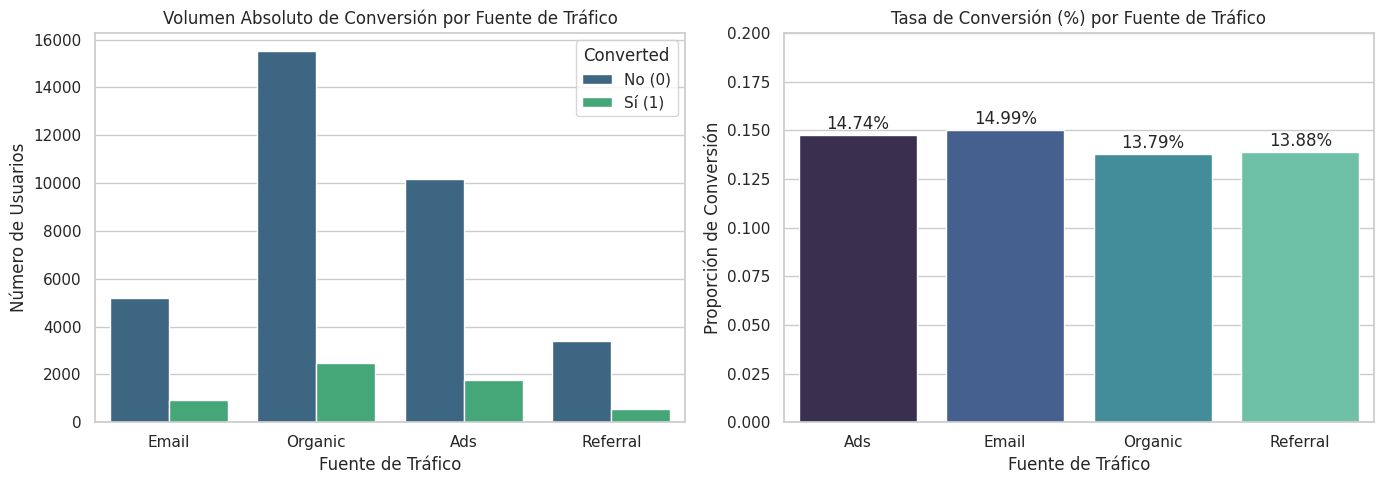

In [18]:
# Configuración de estilo
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Cantidad absoluta de usuarios por canal y conversión
sns.countplot(data=df, x='traffic_source', hue='converted', ax=axes[0], palette='viridis')
axes[0].set_title('Volumen Absoluto de Conversión por Fuente de Tráfico')
axes[0].set_xlabel('Fuente de Tráfico')
axes[0].set_ylabel('Número de Usuarios')
axes[0].legend(title='Converted', labels=['No (0)', 'Sí (1)'])

# Proporción (Tasa de conversión) por canal
df_prop = df.groupby('traffic_source')['converted'].mean().reset_index()
sns.barplot(data=df_prop, x='traffic_source', y='converted', ax=axes[1], palette='mako')
axes[1].set_title('Tasa de Conversión (%) por Fuente de Tráfico')
axes[1].set_xlabel('Fuente de Tráfico')
axes[1].set_ylabel('Proporción de Conversión')
axes[1].set_ylim(0, 0.20)

# Agregar etiquetas de porcentaje sobre cada barra
for p in axes[1].patches:
    axes[1].annotate(f'{p.get_height():.2%}', 
                        (p.get_x() + p.get_width() / 2., p.get_height()), 
                        ha='center', va='center', xytext=(0, 8), 
                        textcoords='offset points')

plt.tight_layout()
plt.show()

#### 📌 Diagnóstico Visual: Fuente de Tráfico vs. Conversión

* **Volumen Masivo vs. Eficiencia Canalizada:** El tráfico *Organic* aporta el mayor volumen absoluto de conversiones ($2,480$ usuarios) debido a la escala de visitas, seguido por *Ads* ($1,759$ conversiones). Sin embargo, al analizar la tasa de conversión relativa, el canal **Email** resulta ser el más eficiente ($14.99\%$), seguido muy de cerca por **Ads** ($14.74\%$).
* **Brecha entre Canales:** La brecha de $1.2$ puntos porcentuales entre el canal más efectivo (*Email*) y el menos efectivo (*Organic* con $13.79\%$) ilustra de forma clara la dependencia detectada en la prueba Chi-cuadrada ($p = 0.0341$).
* **Estrategia de Adquisición:** Mientras que *Email* representa el canal con mayor intención de compra directa, el canal *Organic* requiere optimizaciones en la etapa inicial del embudo (*Top of Funnel*) para filtrar usuarios con mayor propensión a la conversión.

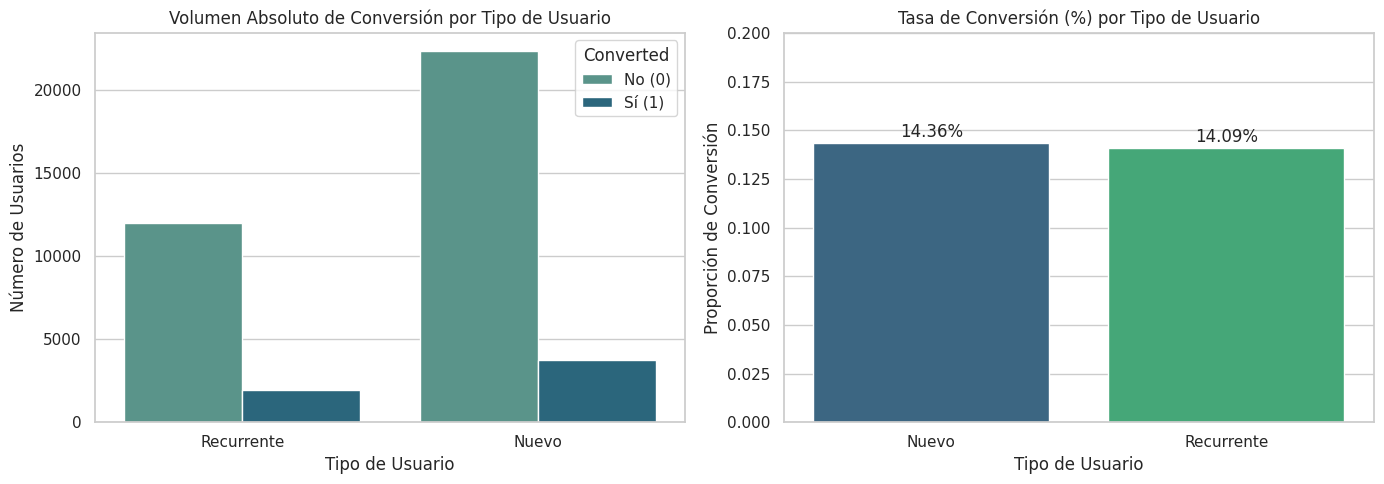

In [19]:
# Configuración del estilo visual
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Cantidad absoluta de usuarios por tipo de usuario y conversión
sns.countplot(data=df, x='user_type', hue='converted', ax=axes[0], palette='crest')
axes[0].set_title('Volumen Absoluto de Conversión por Tipo de Usuario')
axes[0].set_xlabel('Tipo de Usuario')
axes[0].set_ylabel('Número de Usuarios')
axes[0].legend(title='Converted', labels=['No (0)', 'Sí (1)'])

# Proporción (Tasa de conversión) por tipo de usuario
df_user_prop = df.groupby('user_type')['converted'].mean().reset_index()
sns.barplot(data=df_user_prop, x='user_type', y='converted', ax=axes[1], palette='viridis')
axes[1].set_title('Tasa de Conversión (%) por Tipo de Usuario')
axes[1].set_xlabel('Tipo de Usuario')
axes[1].set_ylabel('Proporción de Conversión')
axes[1].set_ylim(0, 0.20)

# Agregar etiquetas de porcentaje sobre cada barra
for p in axes[1].patches:
    axes[1].annotate(f'{p.get_height():.2%}', 
                     (p.get_x() + p.get_width() / 2., p.get_height()), 
                     ha='center', va='center', xytext=(0, 8), 
                     textcoords='offset points')

plt.tight_layout()
plt.show()

#### 📌 Diagnóstico Visual: Tipo de Usuario vs. Conversión

* **Distribución del Volumen:** Los usuarios **Nuevos** representan el mayor volumen de la audiencia y aportan más conversiones absolutas ($3,738$ usuarios) en comparación con los **Recurrentes** ($1,968$ usuarios).
* **Paridad de Rendimiento:** A pesar de la disparidad en volumen de visitas, la tasa de conversión es prácticamente idéntica entre ambos perfiles ($14.36\%$ en usuarios Nuevos vs. $14.09\%$ en Recurrentes, una diferencia de solo $0.27$ puntos porcentuales).
* **Consistencia Estadística:** La paridad visual valida gráficamente la prueba Chi-cuadrada ($p = 0.4736$), confirmando que la efectividad del sitio no depende de la antigüedad del usuario.

## Resumen Ejecutivo y Recomendaciones de Negocio (Executive Insights)

Esta sección sintetiza los hallazgos del análisis estadístico e inferencial del experimento A/B en recomendaciones accionables orientadas a maximizar la rentabilidad del E-Commerce.

---

### 🌟 Síntesis de Resultados del Experimento A/B

#### 🔍 **1. Evaluación del Rendimiento de Página (Control A vs. Variante B)**
* **Ticket Promedio (AOV):** La Versión B registró un gasto promedio significativamente mayor entre los usuarios convertidos ($\Delta = +\$7.66\text{ USD}$), incrementando el ticket de $\$61.09$ a $\$68.75$. La prueba $t$ de Welch confirmó significancia estadística ($p = 3.62 \times 10^{-21} < 0.05$).
  * *Interpretación:* La Variante B fomenta carritos de mayor valor e incentiva la venta de productos de mayor margen (*upselling / cross-selling*).
* **Tasa de Conversión (CR):** La Versión B alcanzó una tasa de conversión del $15.96\%$ frente al $12.57\%$ de la Versión A (un incremento relativo del $\sim 27\%$). La prueba $Z$ de proporciones confirmó la validez estadística ($p = 3.76 \times 10^{-22} < 0.05$).
  * *Interpretación:* La Variante B supera al control en ambos frentes del embudo (volumen de conversión y valor promedio por transacción), maximizando el ingreso por visitante (ARPU).

---

#### 📊 **2. Atribución por Fuente de Tráfico**
* **Volumen vs. Eficiencia:** El tráfico *Organic* aportó el mayor volumen bruto de conversiones ($2,480$ usuarios), mientras que *Email* ($14.99\%$) y *Ads* ($14.74\%$) lograron las tasas de conversión relativas más altas. La prueba Chi-cuadrada confirmós dependencia entre el canal y la conversión ($p = 0.0341$).
    * *Interpretación:* El canal de *Email* atrae a usuarios con alta intención de compra directa. En contraste, el tráfico orgánico requiere optimización en la parte alta del embudo (*Top of Funnel*) para calificar mejor al tráfico entrante.

---

#### 👤 **3. Cohortes de Usuario e Interacción**
* **Independencia por Historial:** Los usuarios Nuevos ($14.36\%$) y Recurrentes ($14.09\%$) convirtieron a tasas prácticamente idénticas ($\Delta = 0.27\%$). La prueba Chi-cuadrada desestimó diferencia significativa ($p = 0.4736$).
* **Efecto de Interacción:** El modelo logístico confirmó que la versión B impulsa incrementos en la conversión de forma sólida en ambos segmentos (Nuevos y Recurrentes).
    * *Interpretación:* La landing page B funciona con la misma eficacia universal. No se justifica invertir recursos en personalizar la landing page según el historial del usuario.

---

### 💡 **Recomendaciones Estratégicas para Stakeholders**

1. **Despliegue Total de la Variante B:** Implementar la landing page B al $100\%$ del tráfico global, al haber demostrado superioridad estadística y económica en tasa de conversión y valor de ticket.
2. **Reasignación de Presupuesto publicitario:** Priorizar el presupuesto de marketing hacia campañas de **Email Retargeting** y **Ads pagados** por su elevada tasa de conversión individual.
3. **Optimización de Conversión Orgánica:** Rediseñar las llamadas a la acción (CTA) y ofertas de entrada para el tráfico orgánico dentro de la Versión B, capitalizando su alto volumen de visitas.
4. **Eficiencia en Costos de Desarrollo:** Mantener una arquitectura web única sin segmentación por antigüedad del usuario, ahorrando costos operativos y de mantenimiento de software.